# Assignment 3_Parte 2: Mapas del Perú
**Pregunta:** ¿Dónde llueve más en el Perú en el periodo de enero a mayo de 2025?

# Instalación e importación de librerías

In [33]:
#Instalar paquetes necesarios
#%pip install geopandas folium matplotlib mapclassify


In [34]:
#Importamos librerías necesarias
import json
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.size"] = 11

In [35]:
#Extraemos el archivo de datos y exploramos su contenido
tabla_path = "datos/tabla_final.csv"
tabla = pd.read_csv(tabla_path, dtype={"ubigeo": str})

print("Dimensiones de Tabla:", tabla.shape)
tabla.head()

Dimensiones de Tabla: (25, 9)


,ubigeo,departamento,capital,latitud,longitud,lluvia_total_mm,dias_lluvia_fuerte,declaratorias,prorrogas
0,01,Amazonas,Chachapoyas,-6.23169,-77.86903,427.9,0,8,4
1,02,Áncash,Huaraz,-9.52614,-77.52869,1415.9,11,8,6
2,03,Apurímac,Abancay,-13.63426,-72.88380,820.0,3,7,2
3,04,Arequipa,Arequipa,-16.39899,-71.53747,439.4,3,8,2
4,05,Ayacucho,Ayacucho,-13.16380,-74.22345,500.8,1,8,4


# A3.2.1 Verificar la existencia de 2 caracteres en la columna "ubigeo"

In [36]:
#A3.2.1 Verificar la existencia de 2 caracteres en la columna "ubigeo"
print("Número de caracteres:", tabla["ubigeo"].str.len().value_counts())


Número de caracteres: ubigeo
2    25
Name: count, dtype: int64


# A3.2.2 Cargamos el archivo de geometrías denominado "distritos_peru.geojson"

In [37]:
#A3.2.2 Cargamos el archivo de geometrías denominado "distritos_peru.geojson"
geometrias_path = "datos/distritos_peru.geojson"

In [38]:
# Nota: Código inicial falló por pyogrio (bloqueo de Windows), se usa json como alternativa.

with open(geometrias_path, encoding="utf-8") as f:
    datos_geo = json.load(f)

distritos = gpd.GeoDataFrame.from_features(datos_geo["features"])
distritos.shape


(1874, 5)

In [39]:
#Se verifica el sistema de coordenadas
datos_geo["crs"] #Se aparecia que coordenadas se encuentran en longitud y latitud.

{'type': 'name', 'properties': {'name': 'urn:ogc:def:crs:OGC:1.3:CRS84'}}

### Cruce por ubigeo como texto

<Axes: xlabel='x', ylabel='y'>

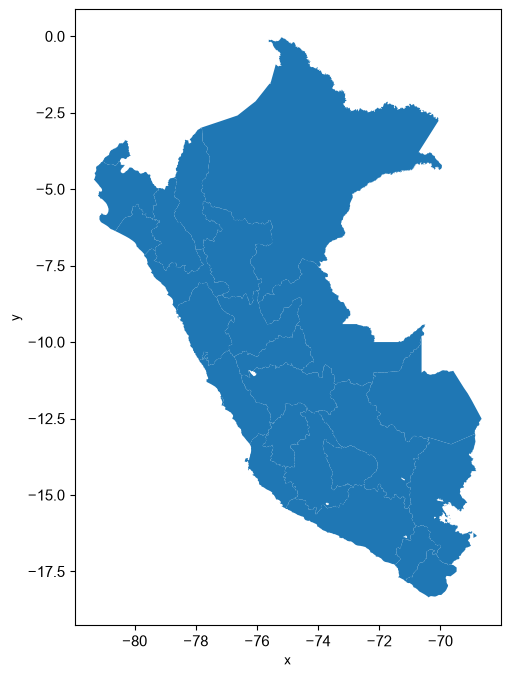

In [40]:
#Convertimos los distritos a  departamentos, considerando que los dos primeros dígitos del ubigeo corresponden al código de departamento

distritos["ubigeo"] = distritos["ubigeo"].str[:2]
geometrias = distritos.dissolve(by="ubigeo", as_index=False)[["ubigeo", "geometry"]] #Retroactivo: para eliminar puntillos blancos en el gráfico.
geometrias["geometry"] = geometrias.buffer(0.001).buffer(-0.001)


geometrias.plot(figsize=(6, 8))  #comprobamos si la función dissolve funcionó correctamente. Resultado: mapa de 25 departamentos.

In [41]:
# Comprobamos si coincide el número de departamentos en los datasets "geometrias" y "tabla"

ubigeos_mapa = set(geometrias["ubigeo"])
ubigeos_tabla = set(tabla["ubigeo"])

# Ubigeos que están en las dos tablas
ambos = ubigeos_mapa & ubigeos_tabla

# Mostramos el número de ubigeos en cada tabla y cuántos coinciden
print("Ubigeos en el mapa:", len(ubigeos_mapa))
print("Ubigeos en la tabla:", len(ubigeos_tabla))
print("Coinciden:", len(ambos))

Ubigeos en el mapa: 25
Ubigeos en la tabla: 25
Coinciden: 25


### Reporte de no cruces y merge (unión)

In [42]:
# No cruce y merge

cruce = geometrias.merge(tabla, on="ubigeo", how="outer", indicator=True)
print(cruce["_merge"].value_counts())
mapa = geometrias.merge(tabla, on="ubigeo", how="left")

_merge
both          25
left_only      0
right_only     0
Name: count, dtype: int64


In [43]:
# Comparamos totales
print("Mapa :", mapa["lluvia_total_mm"].sum())
print("Tabla:", tabla["lluvia_total_mm"].sum())

# Respuesta: Los dos totales coincide, no se perdió data en el cruce.

Mapa : 17709.4
Tabla: 17709.4


In [44]:
mapa

,ubigeo,geometry,departamento,capital,latitud,longitud,lluvia_total_mm,dias_lluvia_fuerte,declaratorias,prorrogas
0,01,"POLYGON ((-78.71229 -5.82949, -78.71228 -5.829...",Amazonas,Chachapoyas,-6.23169,-77.86903,427.9,0,8,4
1,02,"POLYGON ((-78.65833 -8.98607, -78.65831 -8.986...",Áncash,Huaraz,-9.52614,-77.52869,1415.9,11,8,6
2,03,"POLYGON ((-73.84744 -13.40092, -73.84744 -13.4...",Apurímac,Abancay,-13.63426,-72.88380,820.0,3,7,2
3,04,"POLYGON ((-75.07332 -15.44294, -75.07331 -15.4...",Arequipa,Arequipa,-16.39899,-71.53747,439.4,3,8,2
4,05,"POLYGON ((-75.13982 -14.41591, -75.13981 -14.4...",Ayacucho,Ayacucho,-13.16380,-74.22345,500.8,1,8,4
5,06,"POLYGON ((-79.45857 -6.3721, -79.45855 -6.3720...",Cajamarca,Cajamarca,-7.16378,-78.50027,875.7,2,7,2
6,07,"POLYGON ((-77.18796 -11.82856, -77.18795 -11.8...",Callao,Callao,-12.05162,-77.13452,54.0,0,2,0
7,08,"POLYGON ((-73.9811 -12.24991, -73.9811 -12.249...",Cusco,Cusco,-13.53188,-71.96701,801.3,4,9,6
8,09,"POLYGON ((-75.80966 -13.38886, -75.80965 -13.3...",Huancavelica,Huancavelica,-12.78691,-74.97298,930.4,4,8,2
9,10,"POLYGON ((-77.31748 -8.53015, -77.31747 -8.530...",Huánuco,Huánuco,-9.92882,-76.23989,617.0,4,8,5


# A3.2.3 Mapa estático con geopandas

### Mapa de lluvias por departamento

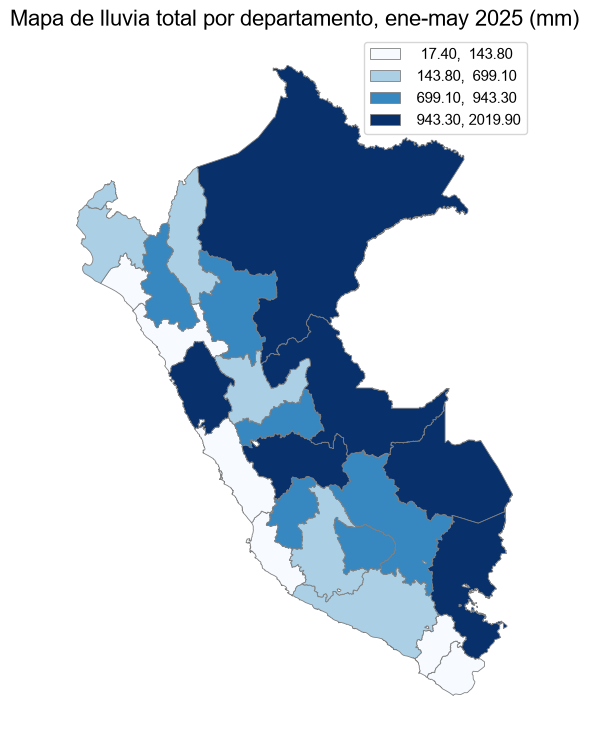

In [45]:
# Mapa de lluvia total por departamento, ene-may 2025 (mm)

mapa.plot(column="lluvia_total_mm", cmap="Blues", scheme="quantiles", k=4, legend=True, edgecolor="gray", linewidth=0.6, figsize=(7, 9))
plt.title("Mapa de lluvia total por departamento, ene-may 2025 (mm)", fontsize=16)
plt.axis("off")
plt.show()

### Mapa de días de lluvia fuerte

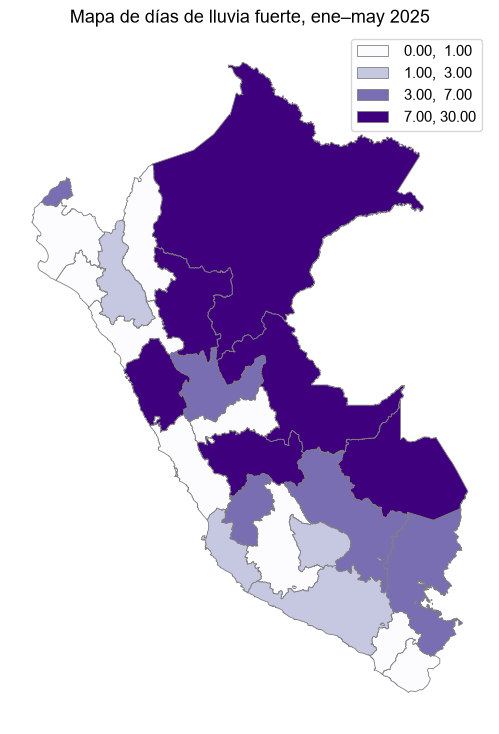

In [46]:
mapa.plot(column="dias_lluvia_fuerte", cmap="Purples", scheme="quantiles", k=4, legend=True, edgecolor="gray", linewidth=0.6, figsize=(7, 9))
plt.title("Mapa de días de lluvia fuerte, ene–may 2025")
plt.axis("off")
plt.show()

# A3.2.4 Mapa interactivo con folium

### Mapa interactivo de lluvias por departamento (usando Choropleth + Tooltip)

In [ ]:
mapa["geometry"] = mapa.simplify(0.01) # Suavizamos la geometría para que el mapa cargue más rápido.
mapa_geojson = json.loads(mapa.to_json()) # Convertimos el mapa a formato GeoJSON para poder usarlo en folium.

datos = mapa.sort_values("lluvia_total_mm", ascending=False).reset_index(drop=True)  # Ordenamos de mayor a menor lluvia
datos["puesto"] = datos.index + 1  

cortes = list(mapa["lluvia_total_mm"].quantile([0, 0.25, 0.5, 0.75, 1]))  # Se agregan cuartiles
mapa_interactivo = folium.Map(location=[-9.0, -75.0], zoom_start=5, tiles="Esri.WorldGrayCanvas")

folium.Choropleth(
    geo_data=mapa_geojson,
    data=mapa,
    columns=["ubigeo", "lluvia_total_mm"],
    key_on="feature.properties.ubigeo",
    fill_color="Reds",
    fill_opacity=0.90,          # Colores más intensos
    bins=cortes,                # Se crearon 4 grupos de igual tamaño para las leyendas
    legend_name="Lluvia total por departamento, ene - may 2025 (mm)",
).add_to(mapa_interactivo)

folium.GeoJson(
    mapa_geojson,
    style_function=lambda x: {"fillOpacity": 0, "color": "gray", "weight": 0.05},
    highlight_function=lambda x: {"weight": 3, "color": "black"},                  #Resalta los bordes de polígonos al ser seleccionados
    tooltip=folium.GeoJsonTooltip(                                                 #Tooltip
        fields=["departamento", "lluvia_total_mm", "dias_lluvia_fuerte"],
        aliases=["Departamento:", "Lluvia total (mm):", "Días de lluvia fuerte:"]),
).add_to(mapa_interactivo)

# Ranking
for _, fila in datos.iterrows():
    punto = fila["geometry"].representative_point()
    numero = f"""<div style="width:20px; height:20px; border-radius:50%; background:white;
                 font:bold 10px Arial; text-align:center; line-height:20px;">{fila['puesto']}</div>"""
    folium.Marker([punto.y, punto.x],
                  icon=folium.DivIcon(html=numero, icon_size=(20, 20), icon_anchor=(10, 10))
                  ).add_to(mapa_interactivo)

# Título y subtítulo
titulo = """
<div style="position:fixed; top:10px; left:60px; z-index:9999; background:white; padding:6px 12px;
            border-radius:6px; box-shadow:0 0 6px rgba(0,0,0,0.3); font-family:Arial;">
  <div style="font-size:17px; font-weight:bold; color:#1f3b70;">Lluvia total por departamento en Perú, enero–mayo 2025</div>
  <div style="font-size:12px; color:gray;">(puesto entre 25 departamentos; milímetros acumulados)</div>

  
</div>"""
mapa_interactivo.get_root().html.add_child(folium.Element(titulo))

# Centramos a Perú para que ocupe toda la ventana
mapa_interactivo.fit_bounds([[-18.4, -81.3], [0.0, -68.7]])

mapa_interactivo.save("mapa_interactivo_lluvia_total.html")
mapa_interactivo

# A3.2.5 Patrón geográfico resaltado en el mapa


### Hallazgos/Observaciones

En todos los mapas se observa un patrón geográfico similar. Los departamentos de la selva presentan, en su mayoría, tonos más oscuros, lo que indica mayor lluvia total y más días de lluvia fuerte entre enero y mayo de 2025. En cambio, los de la región costa muestran tonos más claros; presentaron menos lluvia total y muy pocos días de lluvia fuerte.